# Phase 3.5B — a better speaker-group split proposal

This notebook proposes a third split of the same 5,044 eligible Narration clips. It keeps speaker/session/audio-duplicate components together. Its priorities are a useful validation set for checkpoint choice and a useful test set for final evaluation: balanced gender hours, several independent components, and no held-out set dominated by clips under 3 seconds. Month balance is a secondary diagnostic.

**Status:** proposal only. Running this notebook does not freeze manifests or train/evaluate a model. Do not choose a split using model scores. The source rows and audio are preserved.


In [1]:
from pathlib import Path
import sys
import json
import runpy
import pandas as pd
import matplotlib.pyplot as plt

# Locate the BTP root whether the kernel starts in BTP or BTP/notebooks.
PROJECT = Path.cwd().resolve()
if not (PROJECT / "scripts/phase3_5b_proposal.py").exists():
    PROJECT = PROJECT.parent
assert (PROJECT / "scripts/phase3_5b_proposal.py").exists(), "Open this notebook from the BTP project."
print("Project:", PROJECT)
print("Python:", sys.executable)


Project: /Users/kanchanpotdar/Downloads/BTP
Python: /Users/kanchanpotdar/Downloads/BTP/.venv/bin/python


## 1. Generate the proposal

The companion script uses a fixed random seed and searches assignments at the **component** level. All train-only components remain in training. It also keeps three very large components and the 688-clip short-audio-heavy component in training, because otherwise one held-out set can be dominated by one speaker or tiny clips. It writes a derived Parquet proposal, CSV summary, and JSON audit.

The target held-out size is about 1.9 hours each. Gender balance is judged by **audio hours**, while the under-3-second problem is judged by **clip count**. The search score is only a design tool; it is not CER or model accuracy.


In [2]:
# Execute the deterministic proposal script; it only writes derived files under outputs/.
runpy.run_path(str(PROJECT / "scripts/phase3_5b_proposal.py"), run_name="__main__")
OUT = PROJECT / "outputs/phase3_5b_20261031"
proposal = pd.read_parquet(OUT / "split_proposal.parquet")
audit = json.loads((OUT / "audit.json").read_text())
assert len(proposal) == 5044 and proposal.sample_id.is_unique
print("Rows:", len(proposal), "All design gates passed:", audit["all_gates_pass"])
display(pd.read_csv(OUT / "split_summary.csv", index_col=0).round(3))


{
  "metrics": {
    "train": {
      "hours": 10.851636892361112,
      "clips": 3629,
      "components": 15,
      "female_hours_share": 0.5966389143304568,
      "male_hours_share": 0.39902815001100256,
      "short_clip_share": 0.24028658032515846,
      "largest_component_hours_share": 0.3368659507709798,
      "other_age_hours_share": 0.1056985954427942,
      "later_month_hours_share": 0.8943014045572059
    },
    "validation": {
      "hours": 1.8818083506944445,
      "clips": 732,
      "components": 16,
      "female_hours_share": 0.5087703713186418,
      "male_hours_share": 0.46325860225261123,
      "short_clip_share": 0.1994535519125683,
      "largest_component_hours_share": 0.24135178004247004,
      "other_age_hours_share": 0.6546849914727689,
      "later_month_hours_share": 0.2441017944092839
    },
    "test": {
      "hours": 1.891057482638889,
      "clips": 683,
      "components": 13,
      "female_hours_share": 0.5089859288478096,
      "male_hours_share": 0

,hours,clips,components,female_hours_share,male_hours_share,short_clip_share,largest_component_hours_share,other_age_hours_share,later_month_hours_share
train,10.852,3629.0,15.0,0.597,0.399,0.240,0.337,0.106,0.894
validation,1.882,732.0,16.0,0.509,0.463,0.199,0.241,0.655,0.244
test,1.891,683.0,13.0,0.509,0.491,0.138,0.337,0.596,0.322


## 2. Compare Phases 3, 3.5, and 3.5B

Check the same measurements for all proposals. A lower percentage of short test clips matters because an evaluation dominated by tiny utterances may describe a different task. A low largest-component share means one speaker cannot dominate the aggregate CER. Month mix is displayed, but it does not decide the split by itself.


In [3]:
sources = {
    "Phase 3": (PROJECT / "outputs/phase3_20261031_223422/split_proposal.parquet", "proposed_split"),
    "Phase 3.5": (PROJECT / "outputs/phase3_5_20261031_224609/revised_split_proposal.parquet", "revised_split"),
    "Phase 3.5B": (OUT / "split_proposal.parquet", "phase35b_split"),
}
records = []
for strategy, (path, column) in sources.items():
    data = pd.read_parquet(path)
    for split in ("train", "validation", "test"):
        part = data.loc[data[column].eq(split)]
        total_seconds = part.duration_exact.astype(float).sum()
        component_hours = part.groupby("component_id").duration_exact.sum() / 3600
        records.append({
            "strategy": strategy, "split": split, "clips": len(part),
            "hours": total_seconds / 3600,
            "components": len(component_hours),
            "largest_component_hours_pct": 100 * component_hours.max() * 3600 / total_seconds,
            "female_hours_pct": 100 * part.loc[part.gender.eq("Female"), "duration_exact"].sum() / total_seconds,
            "under_3s_clips_pct": 100 * part.duration_exact.lt(3).mean(),
            "november_2024_hours_pct": 100 * part.loc[part.recording_month.eq("2024-11"), "duration_exact"].sum() / total_seconds,
        })
comparison = pd.DataFrame(records)
display(comparison.round(1))


,strategy,split,clips,hours,components,largest_component_hours_pct,female_hours_pct,under_3s_clips_pct,november_2024_hours_pct
0,Phase 3,train,2876,10.5,11,34.8,58.3,6.9,7.6
1,Phase 3,validation,1428,2.2,7,29.0,56.3,52.9,54.5
2,Phase 3,test,740,1.9,26,7.9,53.7,21.2,96.4
3,Phase 3.5,train,3055,10.2,28,35.7,46.3,10.5,24.0
4,Phase 3.5,validation,542,2.2,6,90.5,98.8,6.3,9.5
5,Phase 3.5,test,1447,2.2,10,29.1,67.7,52.3,54.3
6,Phase 3.5B,train,3629,10.9,15,33.7,59.7,24.0,10.6
7,Phase 3.5B,validation,732,1.9,16,24.1,50.9,19.9,75.6
8,Phase 3.5B,test,683,1.9,13,33.7,50.9,13.8,67.8


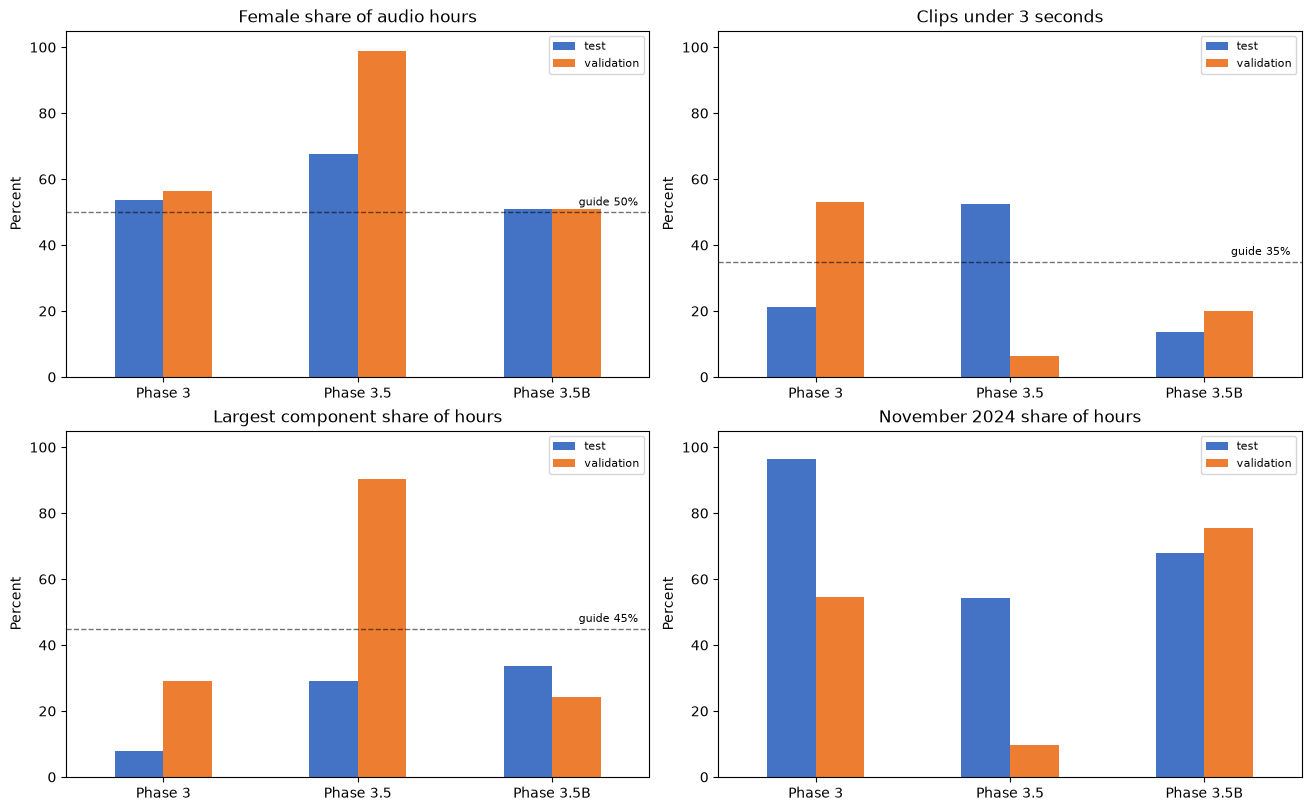

In [4]:
# Four compact plots suitable for comparison in the thesis report.
heldout = comparison.loc[comparison.split.isin(["validation", "test"])].copy()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
plot_cols = [
    ("female_hours_pct", "Female share of audio hours", 50),
    ("under_3s_clips_pct", "Clips under 3 seconds", 35),
    ("largest_component_hours_pct", "Largest component share of hours", 45),
    ("november_2024_hours_pct", "November 2024 share of hours", None),
]
for ax, (col, title, guide) in zip(axes.flat, plot_cols):
    table = heldout.pivot(index="strategy", columns="split", values=col).reindex(sources)
    table.plot.bar(ax=ax, rot=0, color=["#4472c4", "#ed7d31"])
    ax.set_title(title)
    ax.set_ylabel("Percent")
    ax.set_xlabel("")
    ax.set_ylim(0, 105)
    if guide is not None:
        ax.axhline(guide, color="black", linestyle="--", linewidth=1, alpha=0.55)
        ax.text(0.98, guide + 2, f"guide {guide}%", transform=ax.get_yaxis_transform(), ha="right", fontsize=8)
    ax.legend(title="", fontsize=8)
plt.show()


## 3. Leakage and quality gates

Every known speaker group, raw/public speaker ID, recording session and exact decoded waveform hash must appear in one split only. Train-only rows must stay out of validation and test. These are necessary checks; they cannot prove that every speaker identity in the source metadata is correct. One identical transcript may appear across splits without identical audio: report it as prompt overlap, not automatically as audio leakage.


In [5]:
display(pd.Series(audit["gates"], name="passed").to_frame())
print("Cross-split key overlaps:", audit["cross_split_overlaps"])
print("Train-only rows in held-out:", audit["heldout_train_only_rows"])
print("Status:", audit["status"])
assert audit["all_gates_pass"], "Do not freeze: at least one split design gate failed."

# Show any repeated complete reference string spanning splits for manual documentation.
prompt_counts = proposal.groupby("transcript_phase2").phase35b_split.nunique()
shared_prompts = prompt_counts.loc[prompt_counts.gt(1)].index
print("Distinct complete transcript strings crossing splits:", len(shared_prompts))
display(proposal.loc[proposal.transcript_phase2.isin(shared_prompts),
                     ["sample_id", "component_id", "phase35b_split", "transcript_phase2"]]
        .sort_values("transcript_phase2"))


,passed
no_known_cross_split_leakage,True
no_train_only_in_heldout,True
validation_and_test_hours_1_5_to_2_3,True
heldout_female_hours_25_to_75_percent,True
heldout_largest_component_at_most_45_percent,True
heldout_under_3s_clips_at_most_35_percent,True
heldout_at_least_6_components,True


Cross-split key overlaps: {'component_id': 0, 'speaker_group_id': 0, 'speaker_id': 0, 'speaker_id_raw': 0, 'recording_session_id': 0, 'exact_waveform_sha256': 0}
Train-only rows in held-out: 0
Status: proposed_not_frozen
Distinct complete transcript strings crossing splits: 1


,sample_id,component_id,phase35b_split,transcript_phase2
879,A_001126,A_000473,validation,ə
2821,A_003668,A_000006,train,ə
3053,A_003954,A_000166,train,ə


## 4. Decision to record after review

If the audit remains valid, Phase 3.5B is the preferred **proposal** for the first baseline. It avoids Phase 3's short-clip-heavy validation and Phase 3.5's one-speaker, almost-all-female validation plus short-clip-heavy test. It uses about 10.85 hours of training data and about 1.88–1.89 hours each for validation and test. Both held-out sets contain both genders and multiple groups.

Before freezing: check that proposed speaker/session merges and the 42 uncertain-symbol clips are handled under the agreed policy; inspect the shared prompt; record exact source and output hashes; and write the frozen manifests. Once frozen, use the same validation/test split for every model and do not revise it based on CER.
